In [89]:
from nnAudio.features.cqt import CQT, CQT2010v2
import torchaudio
import torch
from matplotlib import pyplot as plt
import lightning as L
from murenn import MuReNNDirect, IDTCWT
import math
import scipy
import numpy as np

CQT kernels created, time used = 0.0107 seconds


(0.5, 4096.0)

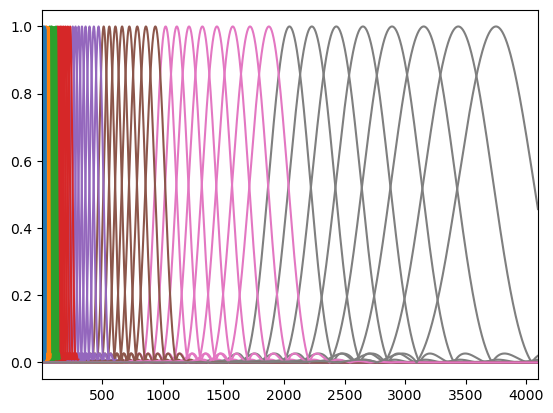

In [72]:
spec = {
    "sr": 44100,
    "seg_length": 2**14,
    "bins_per_octave": 8,
    "n_octave": 8,
    "n_bins": 64,
    "fmin": 22050 // 2**8,
    "fmax": 22050,
    "hop_length": 2**8,
    "n_samples": 1000,
}
cqt_params = {
    "sr": spec["sr"],
    "bins_per_octave": spec["bins_per_octave"],
    "hop_length": spec["hop_length"],
    "n_bins": spec["n_bins"],
    "fmin": spec["fmin"],
    # "fmax": spec["fmax"],
}
col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
closure = CQT(**cqt_params)
cqt_kernels_real = closure.cqt_kernels_real
cqt_kernels_imag = closure.cqt_kernels_imag
for q in range(spec["bins_per_octave"]):
    for j in range(spec["n_octave"]):
        plt.plot(torch.abs(torch.fft.fft(torch.complex(cqt_kernels_real[j*spec["bins_per_octave"]+q,...].squeeze(),cqt_kernels_imag[j*spec["bins_per_octave"]+q,...].squeeze()))), color = col[j])
plt.xlim(0.5, cqt_kernels_real.shape[-1]//2)

Low pass filter created, time used = 0.0005 seconds
num_octave =  8
No early downsampling is required, downsample_factor =  1
Early downsampling filter created,                         time used = 0.0000 seconds
CQT kernels created, time used = 0.0017 seconds


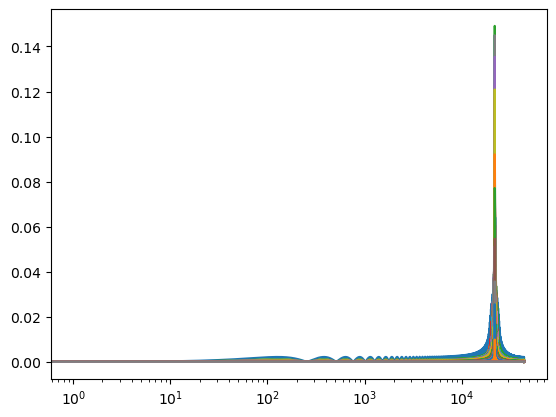

In [93]:
T = 44100
x = torch.zeros(1,1,T)
x[0,0,T//2] =1 
closure.output_format = "Complex"
closure_2010 = CQT2010v2(**cqt_params)
closure_2010.output_format = "Complex"
cqt_x = closure_2010(x)
for q in range(cqt_x.shape[1]):
    plt.semilogx(np.abs(np.fft.fft(scipy.signal.resample(cqt_x[0,q,:], T))))

In [74]:
librosa.icqt?

Signature:
librosa.icqt(
    C: numpy.ndarray,
    *,
    sr: float = 22050,
    hop_length: int = 512,
    fmin: Union[bool, numpy.bool_, int, ForwardRef('np.integer[Any]'), float, ForwardRef('np.floating[Any]'), NoneType] = None,
    bins_per_octave: int = 12,
    tuning: float = 0.0,
    filter_scale: float = 1,
    norm: Optional[float] = 1,
    sparsity: float = 0.01,
    window: Union[str, Tuple[Any, ...], float, Callable[[int], numpy.ndarray], numpy._typing._array_like._SupportsArray[numpy.dtype], numpy._typing._nested_sequence._NestedSequence[numpy._typing._array_like._SupportsArray[numpy.dtype]], bool, int, complex, bytes, numpy._typing._nested_sequence._NestedSequence[Union[bool, int, float, complex, str, bytes]]] = 'hann',
    scale: bool = True,
    length: Optional[int] = None,
    res_type: str = 'soxr_hq',
    dtype: Union[numpy.dtype[Any], NoneType, Type[Any], numpy._typing._dtype_like._SupportsDType[numpy.dtype[Any]], str, Tuple[Any, int], Tuple[Any, Union[SupportsInde

/var/folders/cf/4zrbxdbx151dcqr0zgx8cqzc0000gp/T/ipykernel_26735/2376964835.py:20: ComplexWarning: Casting complex values to real discards the imaginary part
  y_jq[8*j+q]=y[8*j+q]


(0.5, 22050)

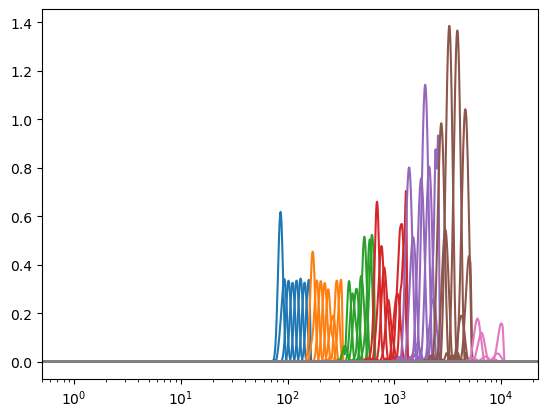

In [95]:
import librosa
T = 44100
x = np.zeros((T))
x[T//2] =1 
y = librosa.cqt(x, **cqt_params, scale=False, tuning=0,sparsity=0)
icqt_params = {
    "sr": spec["sr"],
    "bins_per_octave": spec["bins_per_octave"],
    "hop_length": spec["hop_length"],
    "fmin": spec["fmin"],
    # "fmax": spec["fmax"],
}

col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
for j in range(8):
    for q in range(8):
        y_jq = np.zeros(shape=y.shape)
        y_jq[8*j+q]=y[8*j+q]
        # y = librosa.cqt(x.squeeze().numpy(),**cqt_params, scale=False, tuning=0,sparsity=0, pad_mode = 'reflect')
        # plt.plot(np.abs(np.fft.fft(y[8*j+q,:])), color=col[j])
        y_rec = librosa.icqt(y_jq, **icqt_params, scale=False, tuning=0,sparsity=0)
        plt.semilogx(np.abs(np.fft.fft(y_rec)), color=col[j])
plt.xlim(0.5, T//2)

In [ ]:
teacher = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    win_length=400,
    hop_length=256,
    f_min=64,
    f_max=8000,
    n_mels=40,
    power=2.0,
    center=False)